<div class='bar_title'></div>

*Practical Data Science - Final Project (WS 2026/27)*

# Forecasting German Day-Ahead Electricity Prices
## Part 1: Data Preparation and Exploratory Data Analysis

Group members: Rashad Zarbaliyev, [Member 2], [Member 3]<br>
Data: SMARD, Bundesnetzagentur (CC BY 4.0)

### Running this notebook in Google Colab
Run the next cell first. On your own computer it does nothing. In Colab it gets the project files and installs the missing package.
Because the GitHub repository is private, Colab may ask you to upload the project ZIP (`PDS_Submission_Electricity_Price_Forecasting.zip`).

In [ ]:
# Colab setup (skipped automatically when running locally)
import os, sys, subprocess
if 'google.colab' in sys.modules and not os.path.exists('../src/data_pipeline.py'):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'holidays'])
    repo = 'https://github.com/greenmario2099/pds-electricity-price-forecasting'
    env = dict(os.environ, GIT_TERMINAL_PROMPT='0')
    if not os.path.exists('/content/project'):
        cloned = subprocess.run(['git', 'clone', '-q', '--depth', '1', repo, '/content/project'], env=env).returncode == 0
        if not cloned:
            import glob, zipfile
            from google.colab import files
            print('Repository is private: please upload the project ZIP.')
            name = list(files.upload())[0]
            zipfile.ZipFile(name).extractall('/content/upload')
            pipeline = glob.glob('/content/upload/**/src/data_pipeline.py', recursive=True)[0]
            os.symlink(os.path.dirname(os.path.dirname(pipeline)), '/content/project')
    os.chdir('/content/project/notebooks')
    print('Ready:', os.getcwd())

# Content

* Problem definition
* Loading the data with our pipeline
* Data quality checks
* The target: day-ahead prices
* Seasonal patterns
* Price drivers: load, wind and solar
* Generation mix
* Autocorrelation of prices
* Summary: implications for modeling

## Problem Definition

Every day at 12:00 the European day-ahead auction (run by power exchanges such as EPEX Spot) sets the German wholesale electricity price for each hour of the **next day**.
Utilities, traders, battery operators and flexible industrial consumers need good price forecasts to plan production, bids and battery charging.

**Prediction task:** forecast the hourly day-ahead price (EUR/MWh) of day D, using only information available at noon on day D-1.

*Note: the wind and solar day-ahead forecasts only have to be published by 18:00 on day D-1 (EU Regulation 543/2013, Art. 14), so they are not guaranteed to be available at noon. We use them as a proxy for the weather-based forecasts that traders prepare themselves; the load forecast is published before the auction.*

* Type: regression (time series)
* Target: `price` = day-ahead price of the bidding zone Germany/Luxembourg
* Metric: Mean Absolute Error (MAE), additionally RMSE
* Extension: classify whether an hour will have a negative price (see notebook 03)

## Loading the Data

We downloaded four CSV files from the [SMARD download center](https://www.smard.de/en/downloadcenter/download-market-data/)
(country: Germany, resolution: hour, 01.10.2018 - 17.11.2026). They are stored in the `data/` folder.

To keep the project reproducible, all loading and cleaning steps are implemented in one module: `src/data_pipeline.py`.
All notebooks use the same functions.

In [1]:
import sys
sys.path.append('..')   # so that we can import our own pipeline from the src/ folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data_pipeline import load_data, build_features, FEATURES

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 4)
DATA_DIR = '../data/'

In [2]:
from src.data_pipeline import load_raw, load_actual_generation

raw = load_raw(DATA_DIR)
for name, df in raw.items():
    print(f'{name:20s} {df.shape}')

prices               (71281, 17)
consumption_fc       (71281, 2)
generation_fc        (71281, 6)
generation_actual    (71281, 12)


In [3]:
raw['prices'].iloc[:3, :6]

,Germany/Luxembourg [€/MWh],∅ DE/LU neighbours [€/MWh],Belgium [€/MWh],Denmark 1 [€/MWh],Denmark 2 [€/MWh],France [€/MWh]
2018-10-01 00:00:00+02:00,59.53,NaN,59.53,50.32,50.32,59.53
2018-10-01 01:00:00+02:00,56.10,NaN,56.10,50.43,50.43,56.10
2018-10-01 02:00:00+02:00,51.41,NaN,51.41,42.40,42.40,51.41


The price file also contains the prices of neighbouring countries. We do **not** use them as features:
they are determined in the same auction as the German price and would therefore leak the target.

## Data Quality Checks

### Time index and daylight saving time

SMARD reports local German time. At the switch to summer time one hour is missing, at the switch to winter time one hour appears twice.
The pipeline therefore builds a clean UTC index (one row per hour) and converts it to German time. Let's check the October 2025 switch:

In [4]:
raw['prices'].loc['2025-10-26 01:00':'2025-10-26 04:00'].iloc[:, :1]

,Germany/Luxembourg [€/MWh]
2025-10-26 01:00:00+02:00,3.70
2025-10-26 02:00:00+02:00,3.19
2025-10-26 02:00:00+01:00,2.02
2025-10-26 03:00:00+01:00,0.34
2025-10-26 04:00:00+01:00,0.10


The hour 02:00 appears twice (once in summer time +02:00, once in winter time +01:00), so no hour is lost or duplicated.

### Missing values

In [5]:
for name, df in raw.items():
    missing = df.isna().sum()
    print(name, missing[missing > 0].to_dict())

prices {'∅ DE/LU neighbours [€/MWh]': 9961, 'Poland [€/MWh]': 9961, 'DE/AT/LU [€/MWh]': 71281}
consumption_fc {'grid load [MWh]': 24, 'Residual load [MWh]': 24}
generation_fc {}
generation_actual {'Biomass [MWh]': 7, 'Hydropower [MWh]': 7, 'Wind offshore [MWh]': 7, 'Wind onshore [MWh]': 7, 'Photovoltaics [MWh]': 7, 'Other renewable [MWh]': 7, 'Nuclear [MWh]': 24540, 'Lignite [MWh]': 7, 'Hard coal [MWh]': 7, 'Fossil gas [MWh]': 7, 'Hydro pumped storage [MWh]': 7, 'Other conventional [MWh]': 7}


* **Price file:** only columns we do not use have gaps (old bidding zone DE/AT/LU before Oct 2018, Poland, neighbour average).
* **Consumption forecast:** one complete day is missing (31.01.2020). The pipeline fills it with the forecast of the same hour one week earlier.
* **Actual generation:** nuclear is missing after the nuclear phase-out (April 2023), plus the last hours of the download (not yet published).
  We only use actual generation for EDA.

### The clean dataset

In [6]:
data = load_data(DATA_DIR)
data.head()

,price,load_fc,residual_load_fc,wind_onshore_fc,wind_offshore_fc,solar_fc
2018-10-01 00:00:00+02:00,59.53,44217.12,38357.87,4242.00,1617.25,0.0
2018-10-01 01:00:00+02:00,56.10,42760.17,37006.17,4096.50,1657.50,0.0
2018-10-01 02:00:00+02:00,51.41,42239.56,36337.06,4152.00,1750.50,0.0
2018-10-01 03:00:00+02:00,47.38,42608.70,36277.20,4436.25,1895.25,0.0
2018-10-01 04:00:00+02:00,47.59,44296.03,37341.53,4816.25,2138.25,0.0


In [7]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 71281 entries, 2018-10-01 00:00:00+02:00 to 2026-11-17 23:00:00+01:00
Freq: h
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   price             71281 non-null  float64
 1   load_fc           71281 non-null  float64
 2   residual_load_fc  71281 non-null  float64
 3   wind_onshore_fc   71281 non-null  float64
 4   wind_offshore_fc  71281 non-null  float64
 5   solar_fc          71281 non-null  float64
dtypes: float64(6)
memory usage: 3.8 MB


In [8]:
data.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
price,71281.0,96.3,91.3,-500.0,39.3,77.6,120.3,936.3
load_fc,71281.0,54158.2,9109.0,30544.8,46714.2,54000.8,61589.8,77585.8
residual_load_fc,71281.0,32782.3,13729.5,-29003.2,24102.8,33880.2,42364.0,70214.2
wind_onshore_fc,71281.0,11921.4,9356.3,161.2,4608.8,9195.8,16944.0,48121.6
wind_offshore_fc,71281.0,2891.4,1886.2,13.0,1146.2,2736.2,4561.5,7387.5
solar_fc,71281.0,6572.9,10344.5,0.0,0.0,234.8,10210.5,57895.9


71,281 hourly observations and no missing values. The price ranges from -500 to 936 EUR/MWh: the target is very volatile.

**Note on the 15-minute market:** since 1 October 2025, the day-ahead auction trades 15-minute products. SMARD's hourly values
are the averages of the four quarter-hours, so our hourly series remains consistent over the whole period.

## The Target: Day-Ahead Prices

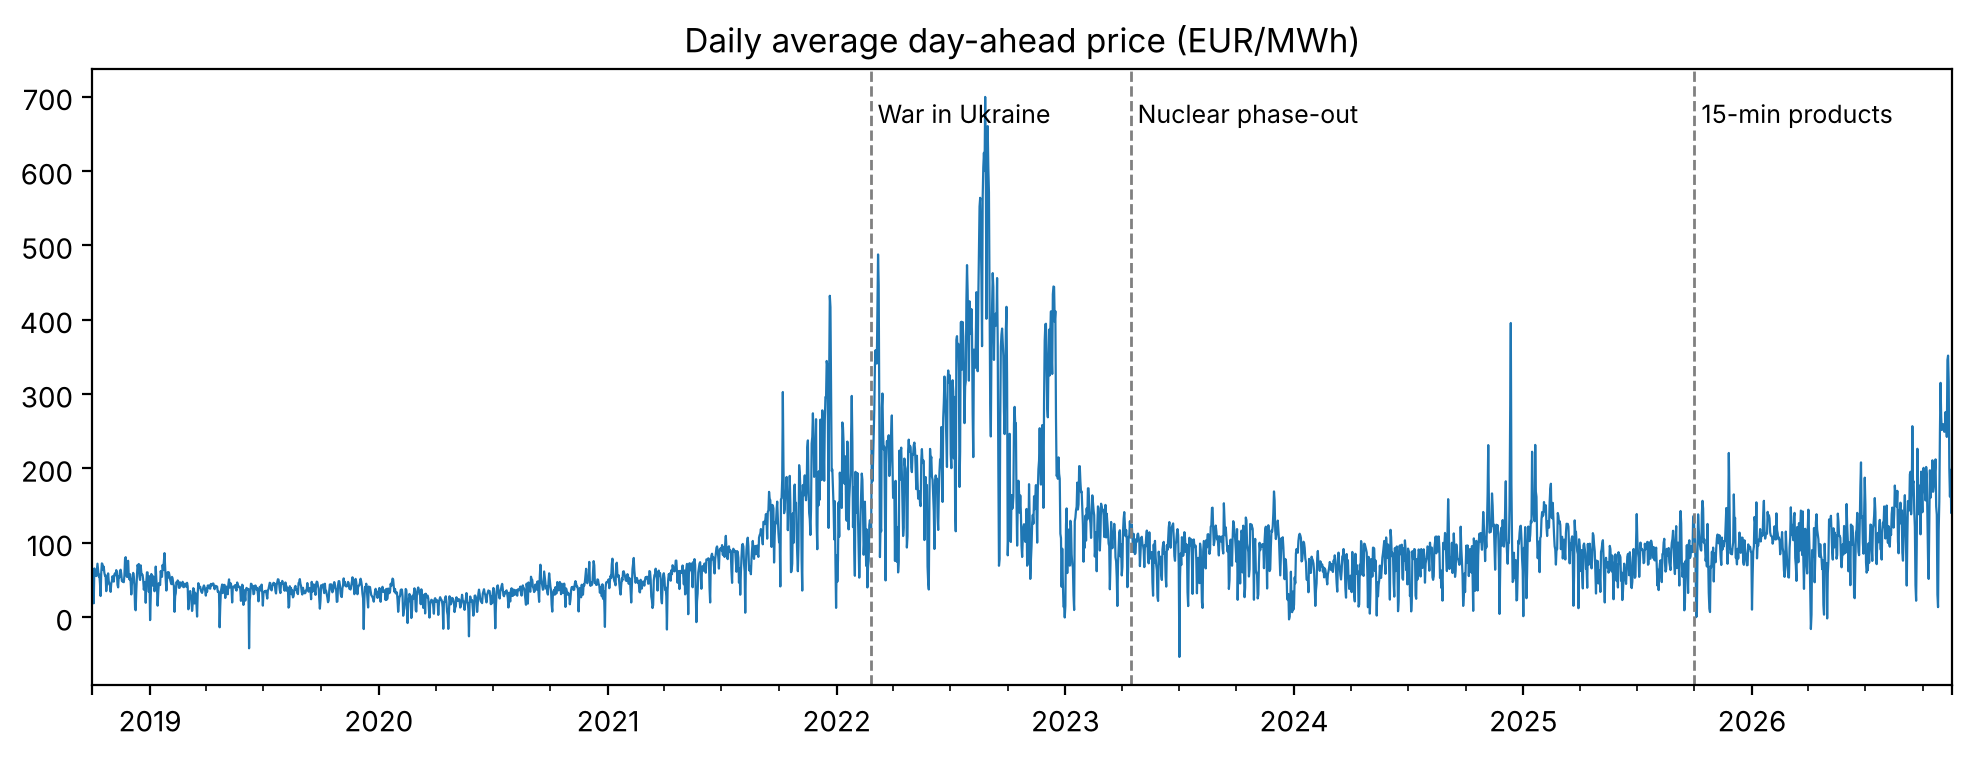

In [9]:
daily = data['price'].resample('D').mean()
ax = daily.plot(title='Daily average day-ahead price (EUR/MWh)', lw=0.8)
for date, label in [('2022-02-24', 'War in Ukraine'), ('2023-04-15', 'Nuclear phase-out'), ('2025-10-01', '15-min products')]:
    ax.axvline(pd.Timestamp(date, tz='Europe/Berlin'), color='grey', ls='--', lw=1)
    ax.text(pd.Timestamp(date, tz='Europe/Berlin'), daily.max() * 0.95, ' ' + label, fontsize=9)

In [10]:
price = data['price']
yearly = price.groupby(price.index.year).agg(['count', 'mean', 'median', 'std', 'min', 'max'])
yearly['negative_hours'] = (price < 0).groupby(price.index.year).sum()
yearly['hours_above_300'] = (price > 300).groupby(price.index.year).sum()
yearly.round(1)

,count,mean,median,std,min,max,negative_hours,hours_above_300
2018,2209,52.6,51.8,18.6,-19.4,128.3,27,0
2019,8760,37.7,38.1,15.5,-90.0,121.5,211,0
2020,8784,30.5,31.0,17.5,-83.9,200.0,298,0
2021,8760,96.8,75.5,73.7,-69.0,620.0,139,224
2022,8760,235.4,208.3,142.8,-19.0,871.0,69,2346
2023,8760,95.2,98.0,47.6,-500.0,524.3,301,3
2024,8784,78.5,79.6,52.7,-135.4,936.3,457,41
2025,8760,89.3,92.4,52.1,-250.3,583.4,573,40
2026,7704,121.0,119.1,76.3,-499.0,697.3,462,143


**Observations**

* 2018-2020: low and stable prices (30-50 EUR/MWh).
* 2021-2022: energy crisis with extreme prices (mean 235 EUR/MWh in 2022).
* Since 2023: a new, higher price level with large fluctuations. 2026 so far is more expensive than 2024-2025.
* Negative prices became much more frequent: 573 hours in 2025.

The price level shifts over time. This is important for modeling: we will use only recent years for training
and include the recent price level as a feature.

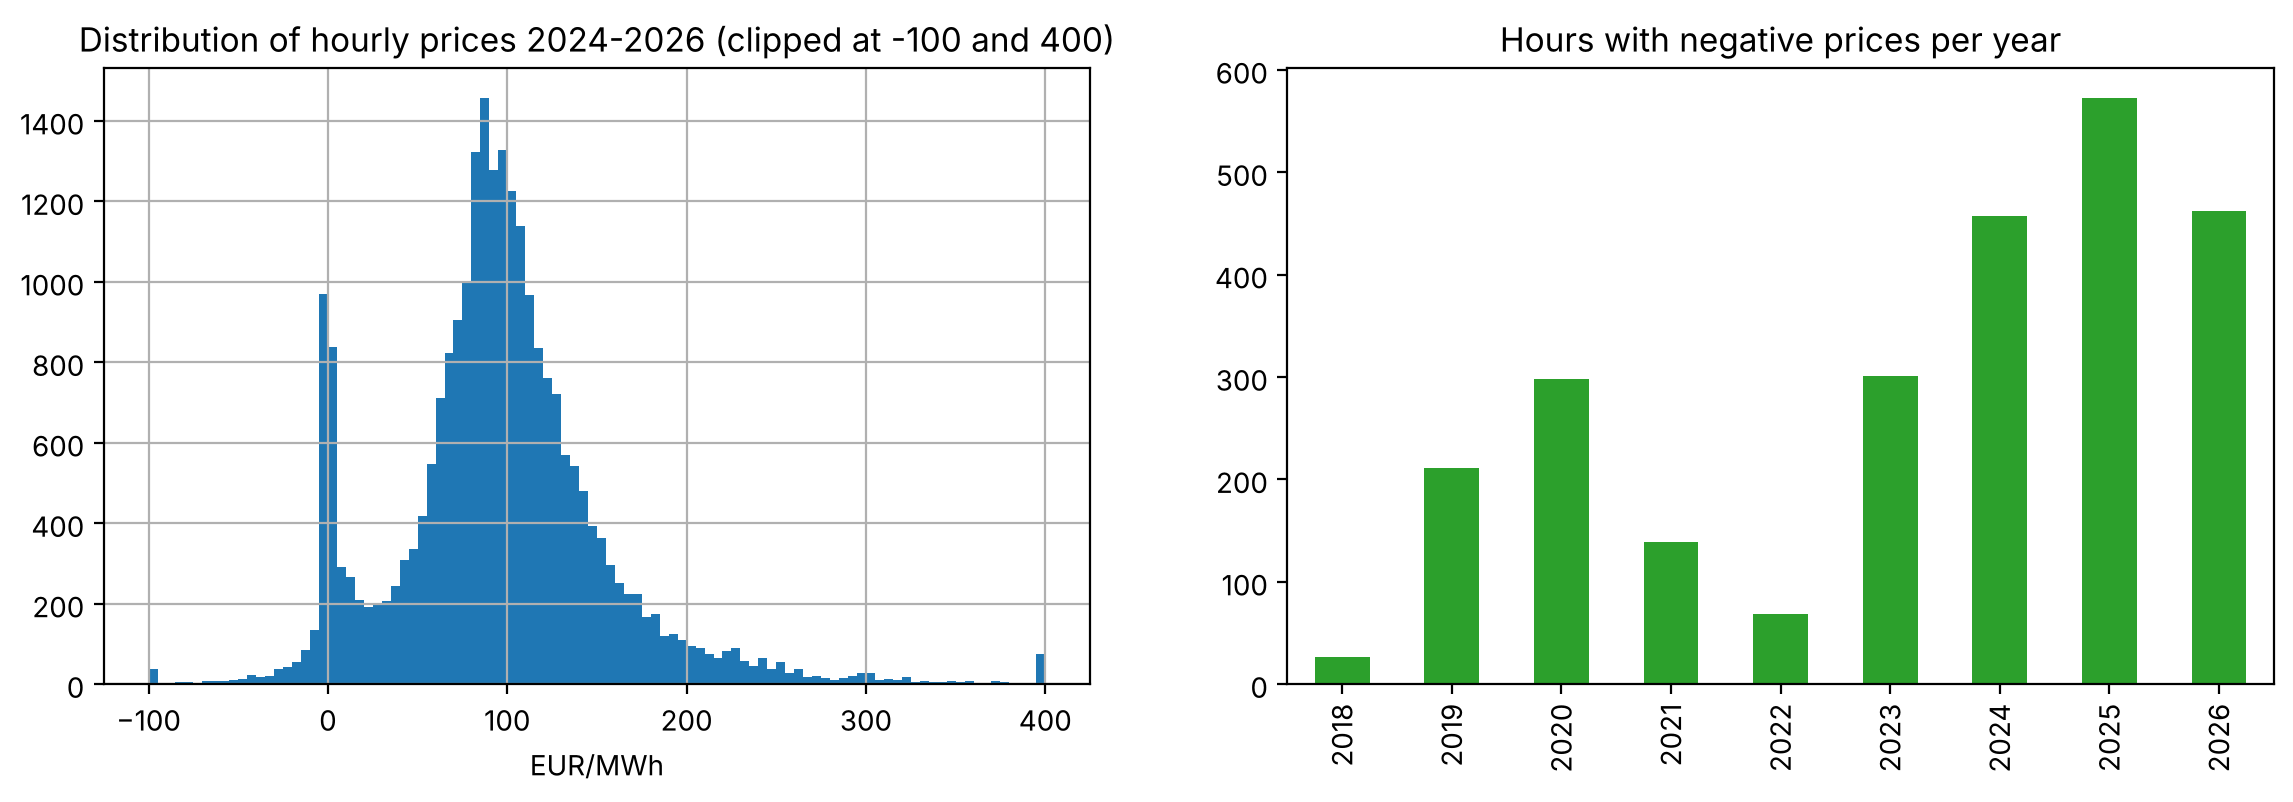

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
recent = data.loc['2024':]
recent['price'].clip(-100, 400).hist(bins=100, ax=axes[0])
axes[0].set_title('Distribution of hourly prices 2024-2026 (clipped at -100 and 400)')
axes[0].set_xlabel('EUR/MWh')

yearly['negative_hours'].plot(kind='bar', ax=axes[1], color='tab:green', title='Hours with negative prices per year');

## Seasonal Patterns

### Daily profile

The daily price profile changed a lot: with the growth of solar power, prices around noon dropped strongly ("duck curve").

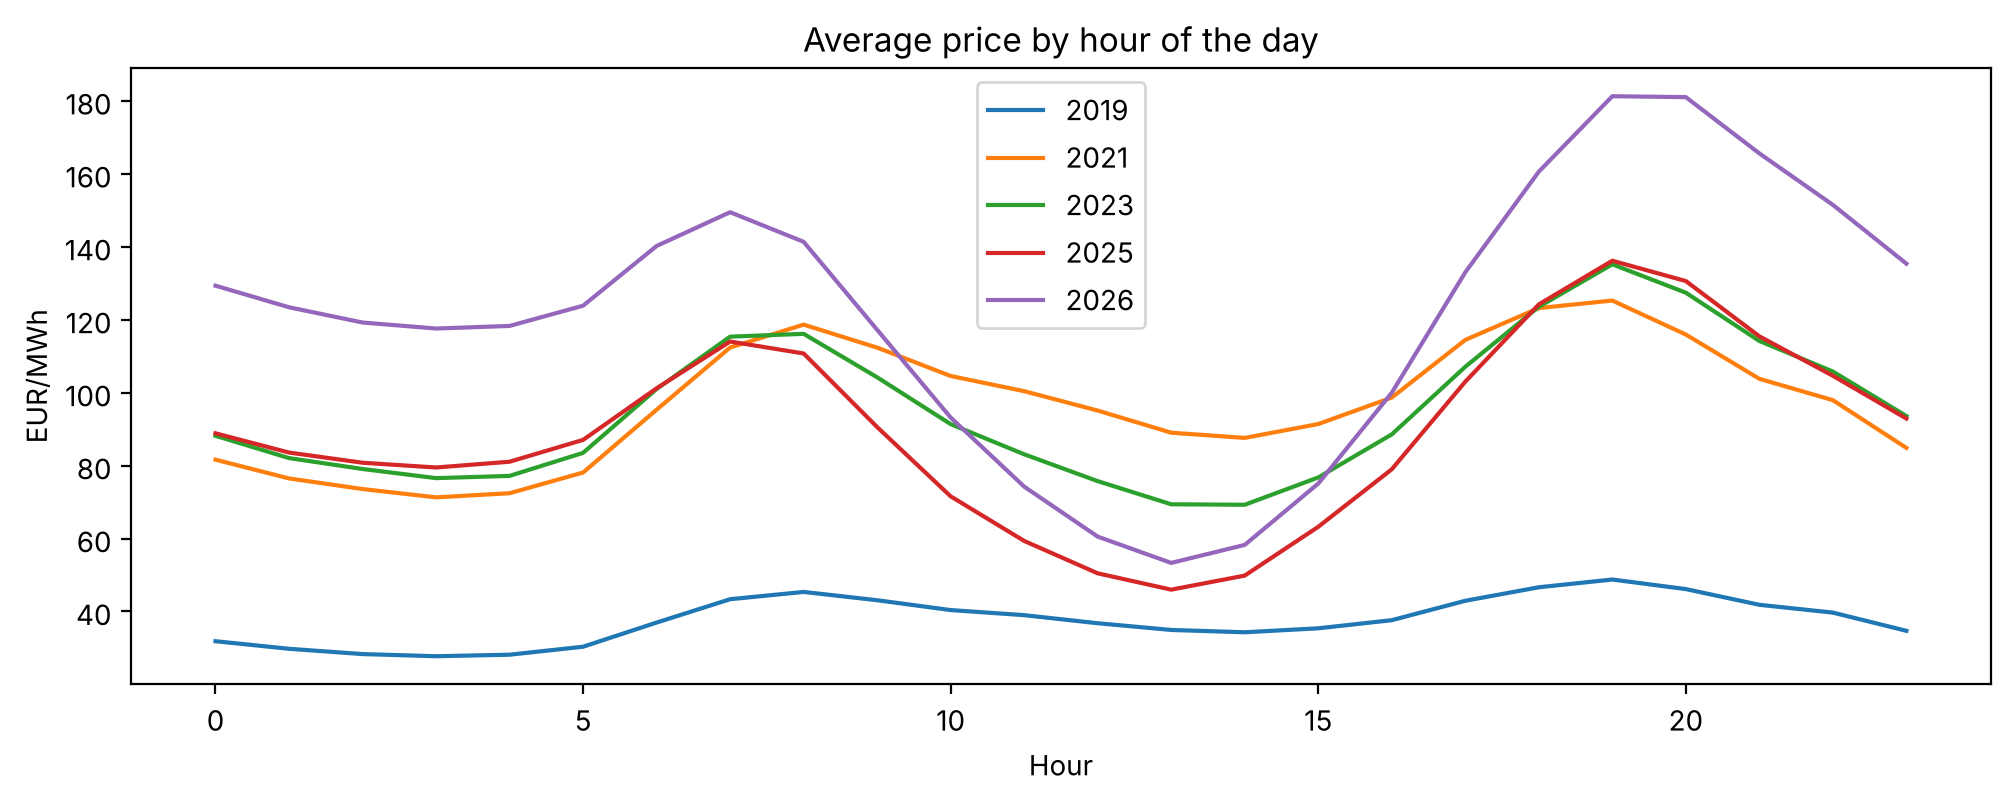

In [12]:
fig, ax = plt.subplots()
for year in [2019, 2021, 2023, 2025, 2026]:
    subset = price[price.index.year == year]
    subset.groupby(subset.index.hour).mean().plot(ax=ax, label=year)
ax.set_title('Average price by hour of the day')
ax.set_xlabel('Hour')
ax.set_ylabel('EUR/MWh')
ax.legend();

### Hour x month heatmap (2025)

In summer the midday hours are cheapest (solar), in winter the evening peak is most expensive.

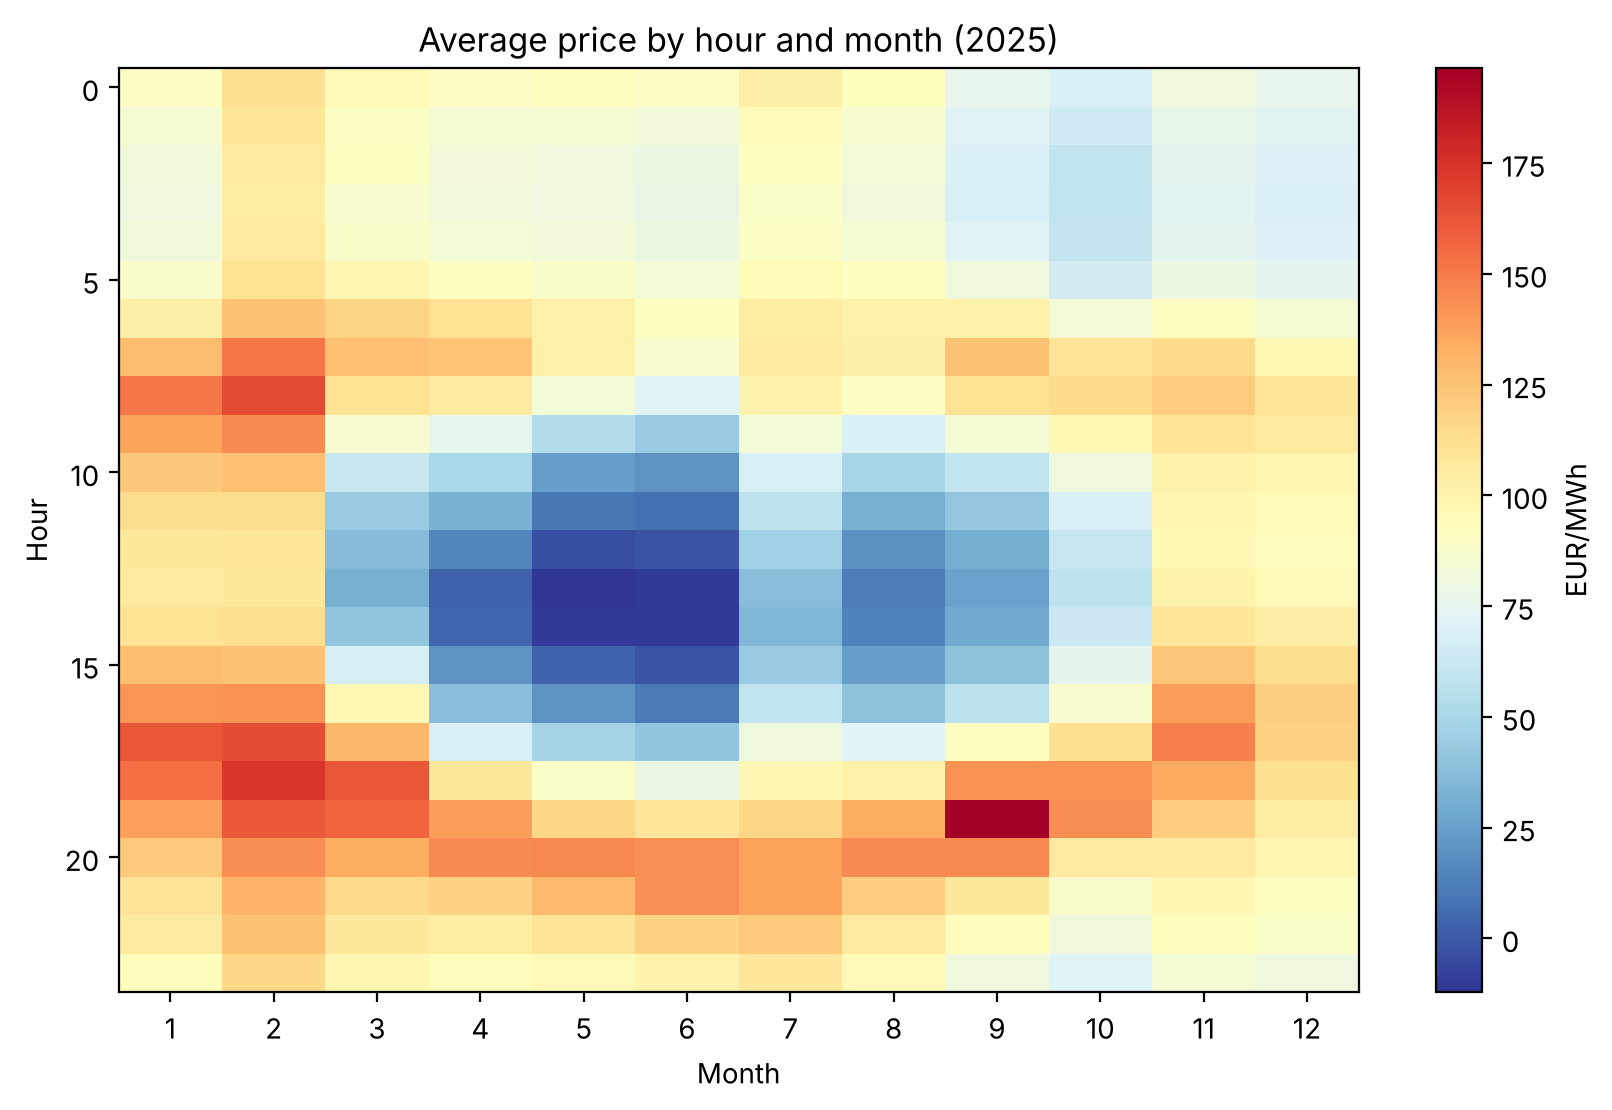

In [13]:
p25 = price.loc['2025']
heat = p25.groupby([p25.index.hour, p25.index.month]).mean().unstack()
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(heat, aspect='auto', cmap='RdYlBu_r')
ax.set_xlabel('Month')
ax.set_ylabel('Hour')
ax.set_xticks(range(12))
ax.set_xticklabels(range(1, 13))
plt.colorbar(im, label='EUR/MWh')
ax.set_title('Average price by hour and month (2025)');

### Weekly profile and holidays

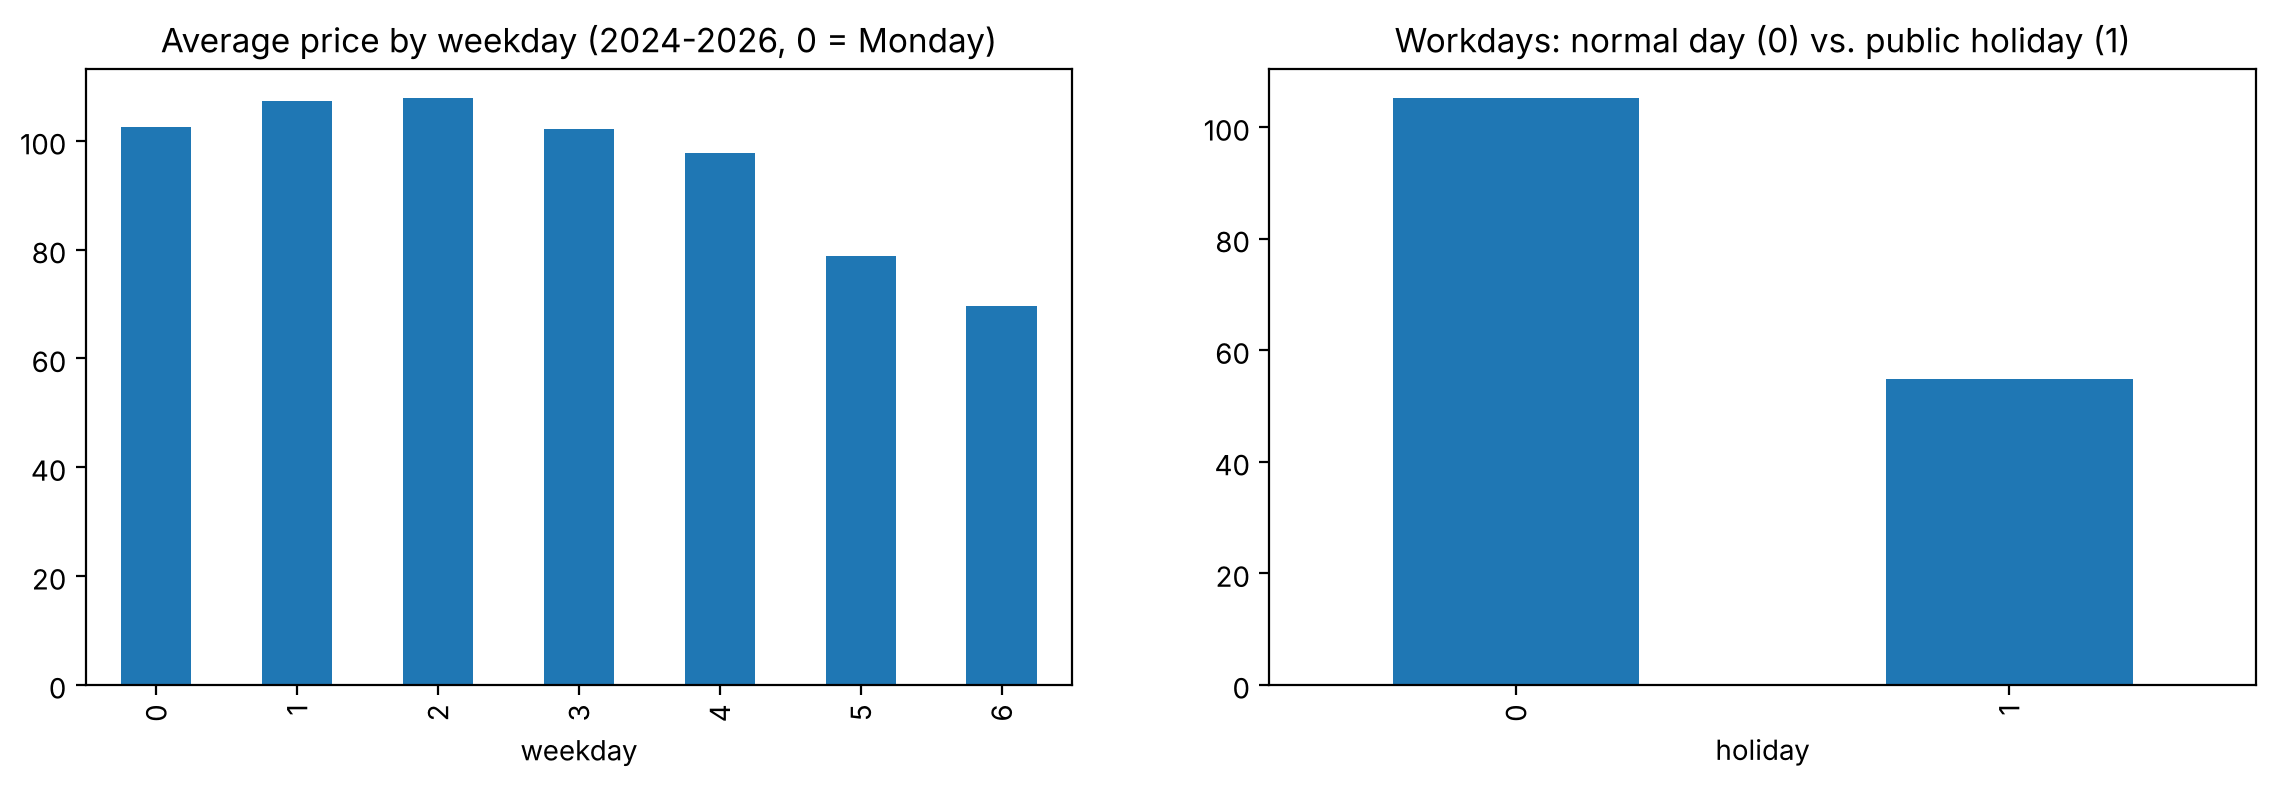

In [14]:
features = build_features(data)
recent = features.loc['2024':]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
recent.groupby('weekday')['price'].mean().plot(kind='bar', ax=axes[0], title='Average price by weekday (2024-2026, 0 = Monday)')
recent[recent['weekday'] < 5].groupby('holiday')['price'].mean().plot(kind='bar', ax=axes[1],
                                                                    title='Workdays: normal day (0) vs. public holiday (1)');

Weekends and public holidays are cheaper because industrial demand is lower. Both are included as calendar features.

## Price Drivers: Load, Wind and Solar

### The merit order

Power plants are dispatched in the order of their marginal costs: first renewables (almost zero costs), then lignite and coal, and finally gas.
The **residual load** (load minus wind and solar) is the demand that conventional plants must cover. The higher it is, the more expensive
the last plant needed, and the higher the price.

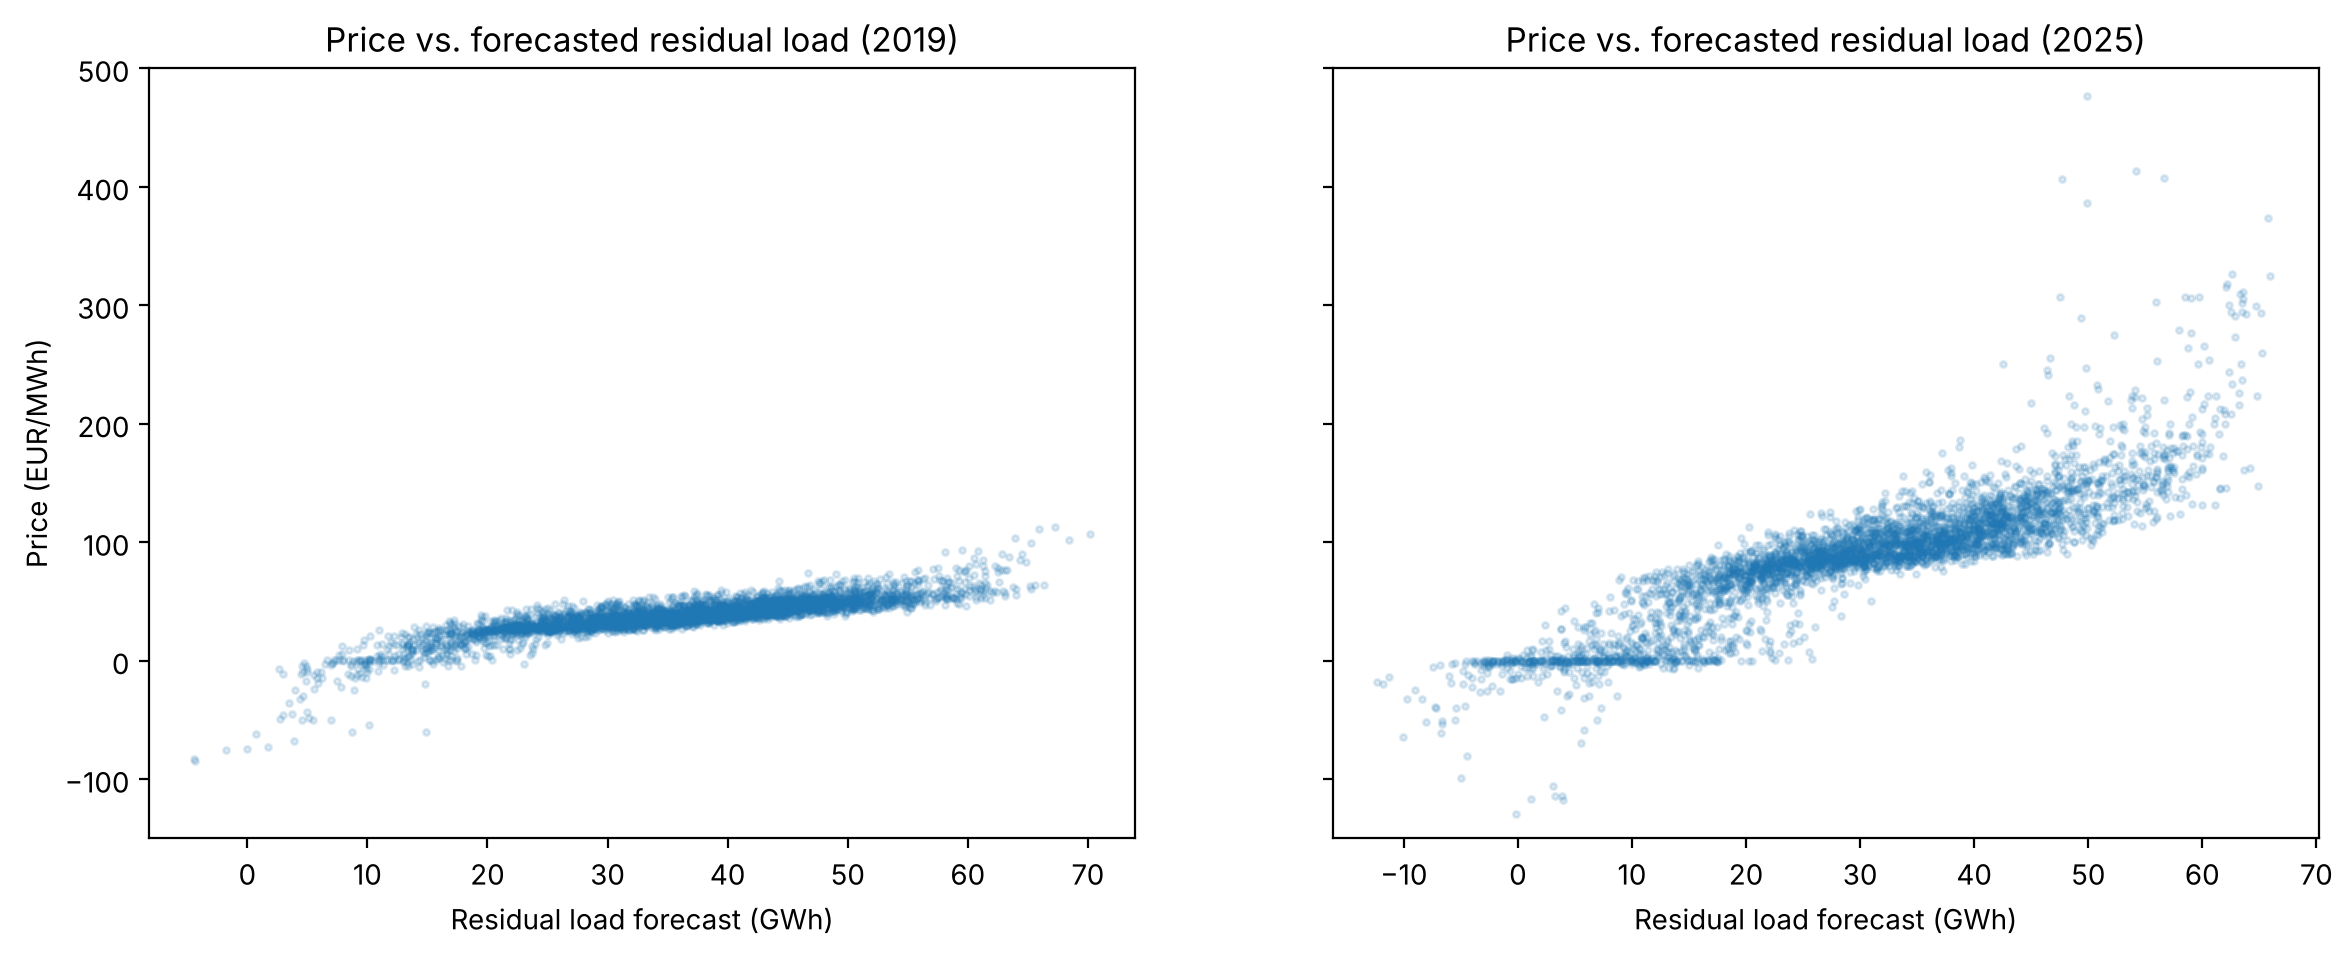

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, year in zip(axes, [2019, 2025]):
    subset = data.loc[str(year)].sample(4000, random_state=1)
    ax.scatter(subset['residual_load_fc'] / 1000, subset['price'], alpha=0.15, s=5)
    ax.set_title(f'Price vs. forecasted residual load ({year})')
    ax.set_xlabel('Residual load forecast (GWh)')
axes[0].set_ylabel('Price (EUR/MWh)')
axes[0].set_ylim(-150, 500);

The relationship is clearly increasing and non-linear (steeper at high residual load). Between 2019 and 2025 the curve shifted upwards
(higher fuel and CO2 costs) and extends further to the left (more renewables, more hours with low residual load and negative prices).
Non-linear models such as a random forest or a neural network can capture this shape, a linear regression only approximately.

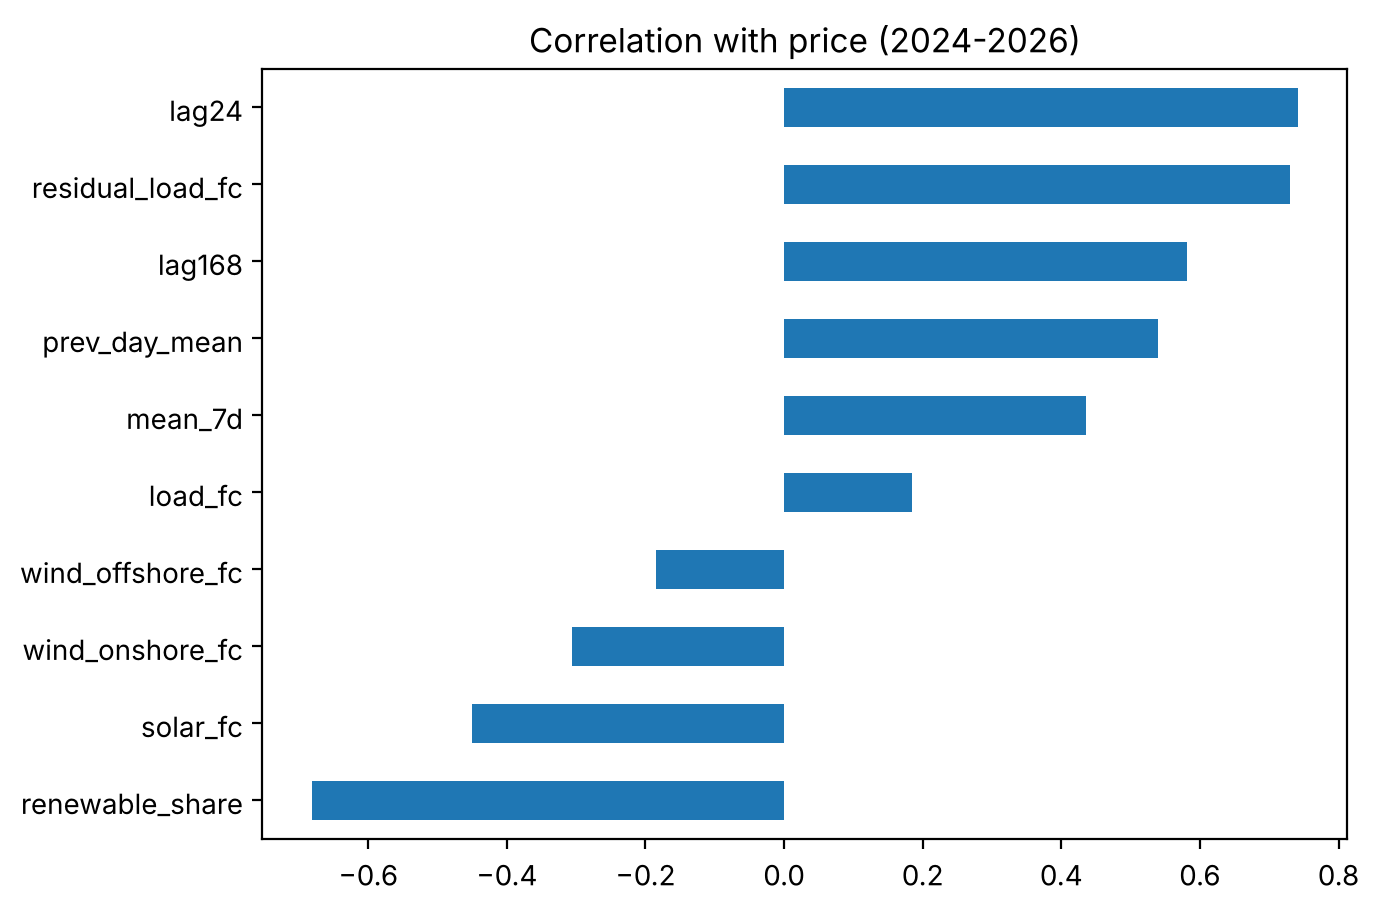

In [16]:
corr_cols = ['price', 'residual_load_fc', 'load_fc', 'wind_onshore_fc', 'wind_offshore_fc', 'solar_fc', 'renewable_share',
             'lag24', 'lag168', 'prev_day_mean', 'mean_7d']
corr = features.loc['2024':, corr_cols].corr()
corr['price'].drop('price').sort_values().plot(kind='barh', figsize=(7, 5), title='Correlation with price (2024-2026)');

* Forecasted residual load is the strongest fundamental driver (r = 0.73).
* Wind and solar lower the price; total load alone is only weakly related.
* Past prices (yesterday, last week) are also strongly correlated: prices are persistent.

### Renewables and negative prices

In [17]:
recent = features.loc['2024':]
bins = pd.cut(recent['renewable_share'], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0, 3])
summary = recent.groupby(bins).agg(hours=('price', 'size'), mean_price=('price', 'mean'), share_negative=('negative', 'mean'))
summary.round(2)

,hours,mean_price,share_negative
renewable_share,,,
"(0.0, 0.2]",5146,145.78,0.00
"(0.2, 0.4]",7091,117.48,0.00
"(0.4, 0.6]",5909,93.30,0.00
"(0.6, 0.8]",4054,59.50,0.04
"(0.8, 1.0]",2175,17.94,0.32
"(1.0, 3.0]",873,-12.41,0.72


When wind and solar forecasts cover 80-100% of the load, about a third of the hours have negative prices; above 100%, almost three quarters do.
`renewable_share` is therefore a key feature for the classification task.

## Generation Mix (Actual Generation)

Actual generation is published only after the fact, so it is **not** a model feature. It helps to understand the structural changes in the market.

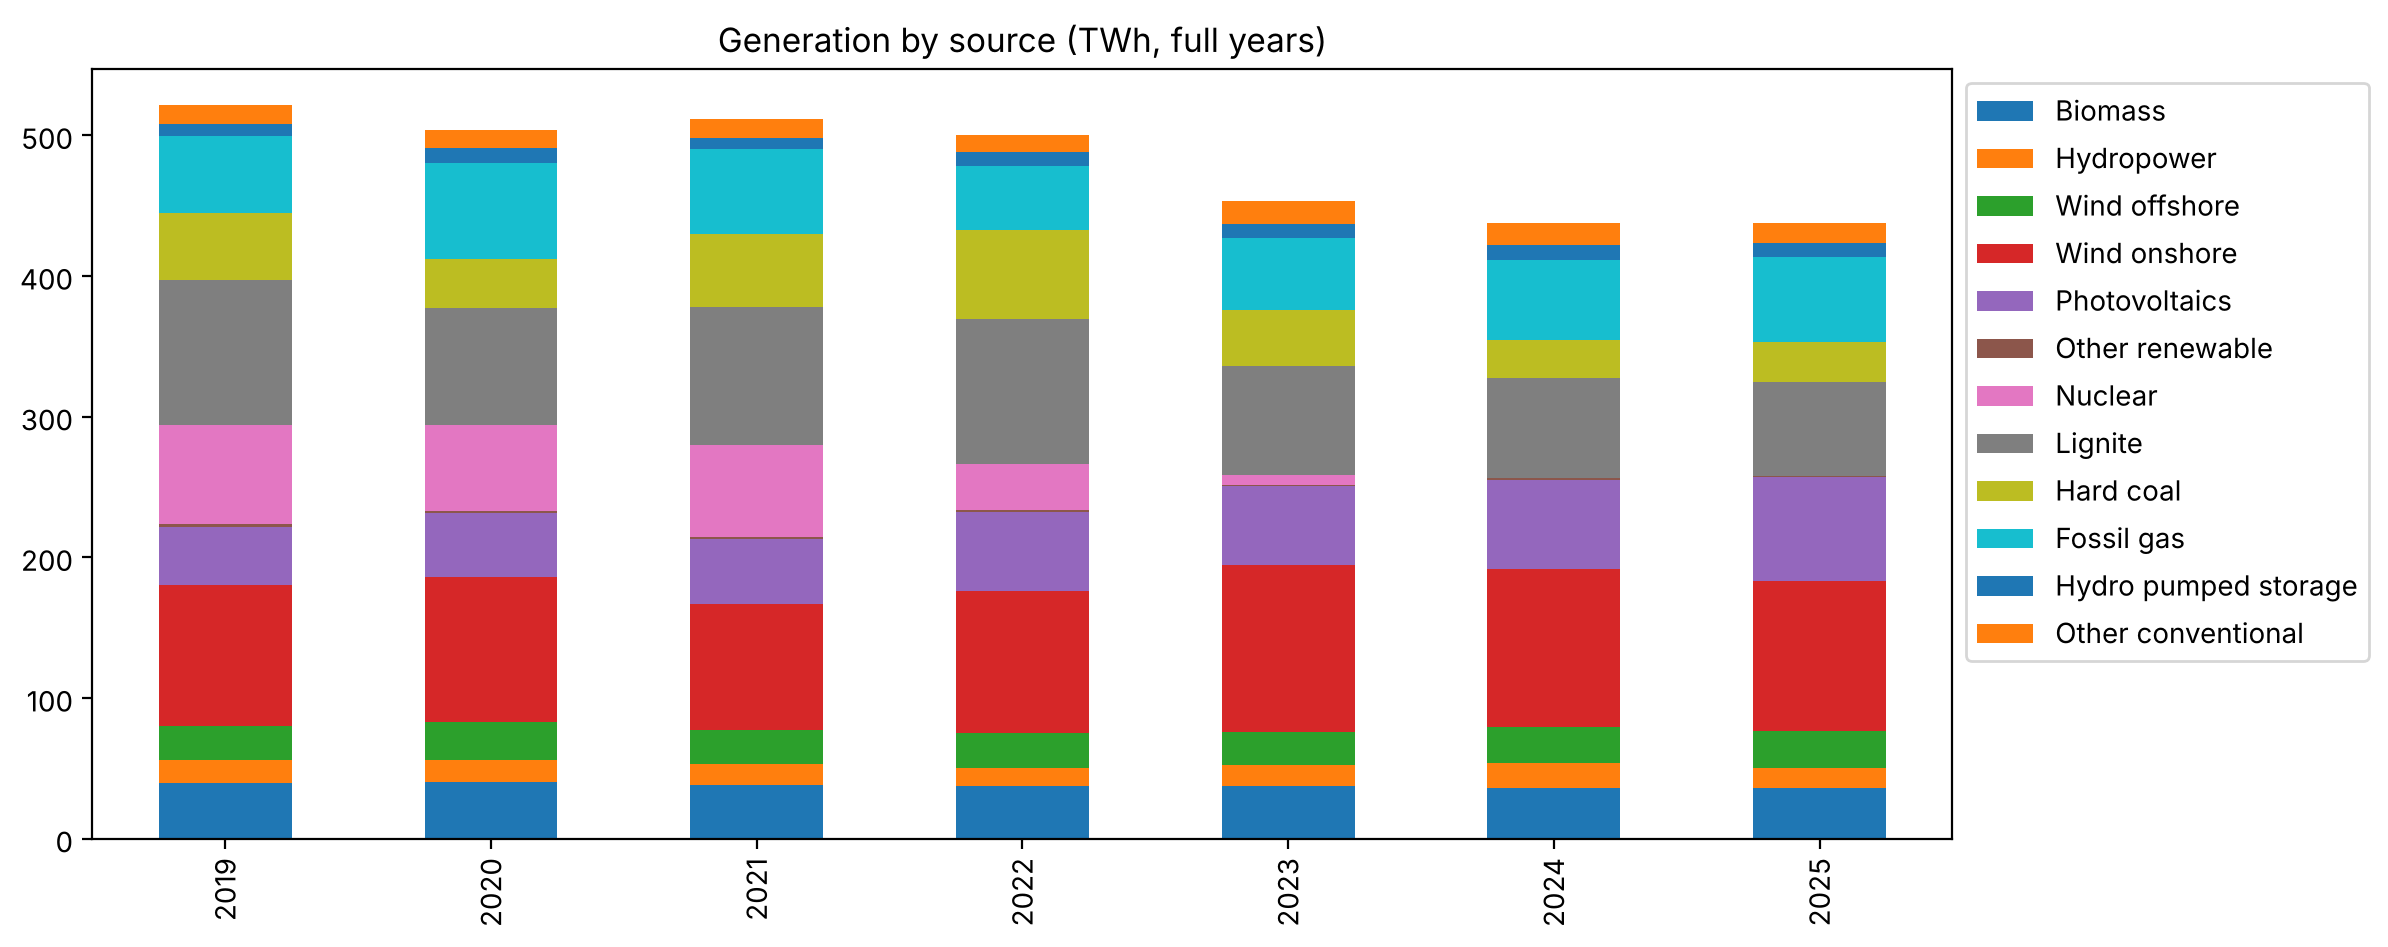

In [18]:
gen = load_actual_generation(DATA_DIR)
yearly_mix = gen.loc['2019':'2025'].groupby(gen.loc['2019':'2025'].index.year).sum() / 1e6
yearly_mix.plot(kind='bar', stacked=True, figsize=(12, 5), title='Generation by source (TWh, full years)').legend(bbox_to_anchor=(1, 1));

In [19]:
share_renewable = yearly_mix[['Biomass', 'Hydropower', 'Wind offshore', 'Wind onshore', 'Photovoltaics', 'Other renewable']].sum(axis=1) / yearly_mix.sum(axis=1)
(share_renewable * 100).round(1).rename('Renewable share of generation (%)')

2019    42.8
2020    46.3
2021    41.9
2022    46.7
2023    55.5
2024    58.5
2025    58.9
Name: Renewable share of generation (%), dtype: float64

Nuclear disappeared in April 2023 and solar generation grew by about 75% (42 TWh in 2019, 74 TWh in 2025). The share of renewables grew strongly.
This explains the changing daily price profile and the increasing number of negative-price hours.

## Autocorrelation of Prices

How strongly is the price correlated with its own past values? This tells us which lags are useful as features.
Note: for day-ahead forecasting we can only use lags of **at least 24 hours** (prices of the forecast day are unknown).

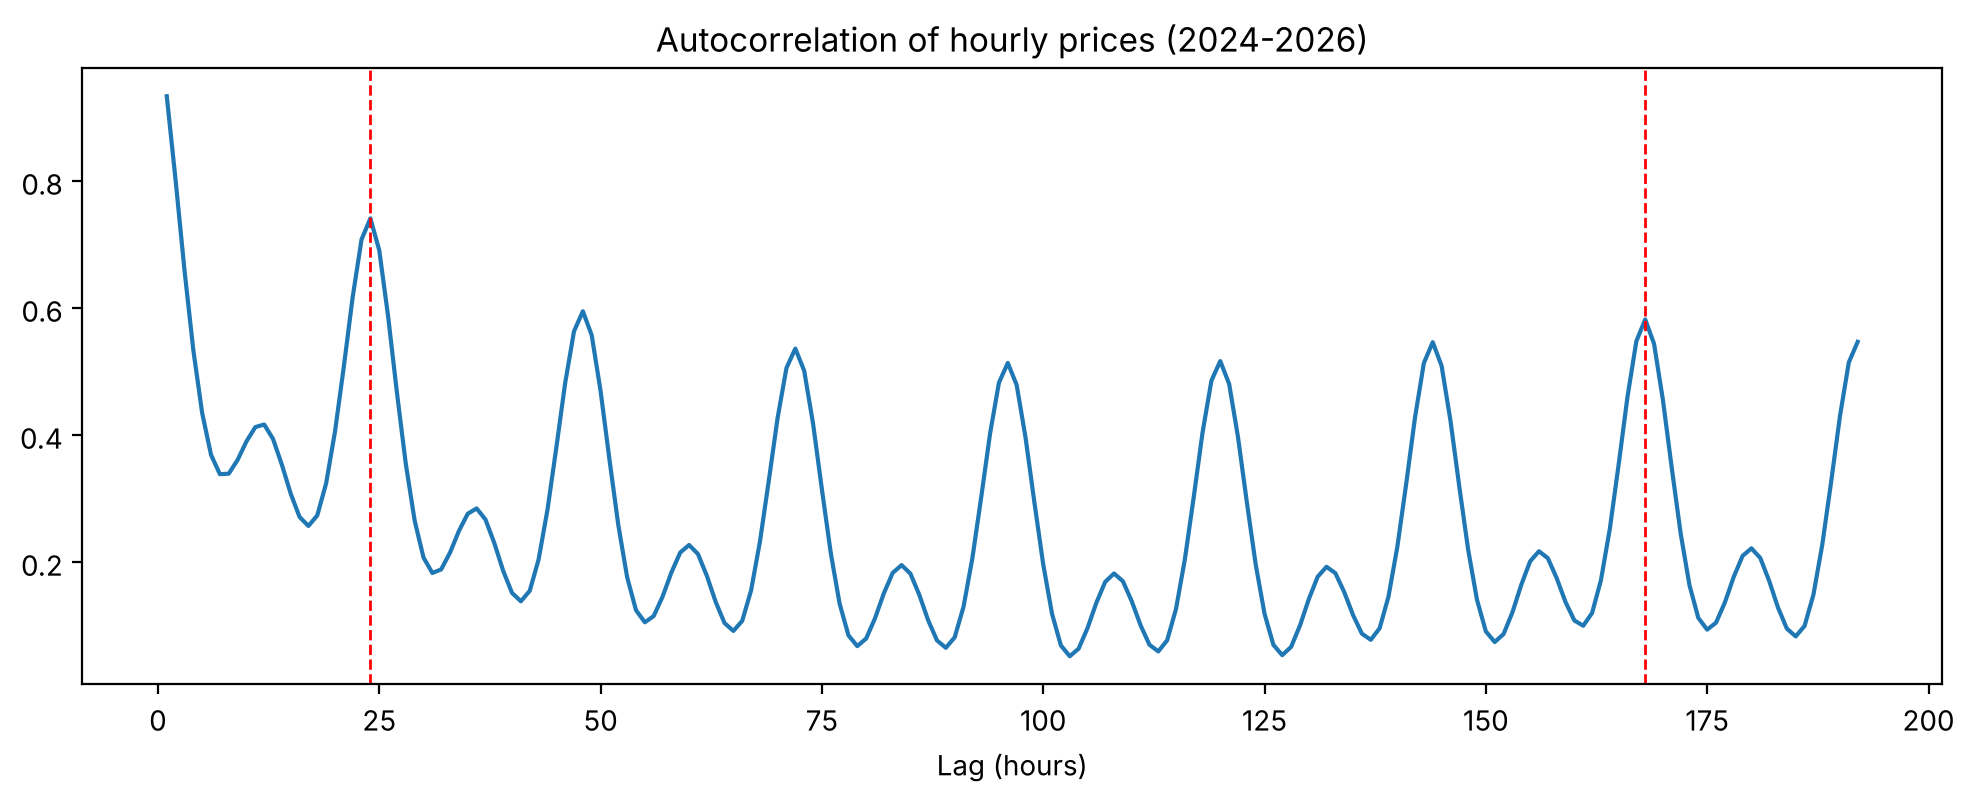

In [20]:
p = data['price'].loc['2024':]
lags = range(1, 24 * 8 + 1)
autocorr = pd.Series([p.autocorr(lag) for lag in lags], index=lags)
ax = autocorr.plot(title='Autocorrelation of hourly prices (2024-2026)')
ax.axvline(24, color='red', ls='--', lw=1)
ax.axvline(168, color='red', ls='--', lw=1)
ax.set_xlabel('Lag (hours)');

Clear peaks at 24 hours (same hour yesterday) and 168 hours (same hour last week). We therefore use `lag24`, `lag48` and `lag168`,
and summary statistics of the previous day and week.

## Summary: Implications for Modeling

| Finding | Modeling decision |
| --- | --- |
| Price level shifts over time (crisis 2022, higher level in 2026) | Train on recent data only, use rolling price-level features (`mean_7d`, `mean_30d`), retrain monthly |
| Residual load drives the price non-linearly | Non-linear models (random forest, neural network) next to a linear baseline |
| Strong daily, weekly and holiday patterns | Calendar features: hour, weekday, month, weekend, holiday |
| Prices are persistent (peaks at lag 24 and 168) | Lagged prices of at least 24 hours |
| Negative prices are frequent when renewables cover the load | Separate classification task with `renewable_share` |
| Neighbour prices and actual generation are not known before the auction | Excluded to avoid data leakage |
| Time series data | Chronological train/validation/test split, no shuffling |

The full list of features is defined in `src/data_pipeline.py`:

In [21]:
print(len(FEATURES), 'features')
FEATURES

27 features


['load_fc',
 'residual_load_fc',
 'wind_onshore_fc',
 'wind_offshore_fc',
 'solar_fc',
 'renewable_share',
 'residual_load_ramp',
 'residual_load_rel_day',
 'residual_load_day_max',
 'residual_load_day_min',
 'residual_load_change_24h',
 'hour',
 'weekday',
 'month',
 'day_of_year',
 'weekend',
 'holiday',
 'lag24',
 'lag48',
 'lag168',
 'same_hour_mean_7d',
 'prev_day_mean',
 'prev_day_min',
 'prev_day_max',
 'mean_7d',
 'mean_30d',
 'std_7d']